# Student Performance Predictor and Educational Analytics

### 1.Data Inspection

#### Loading Dataset and Importing necessary dependencies
---

In [1]:

# Importing necessaries dependencies
import pandas as pd 
import numpy as np 


In [2]:
# Data Loading and initial verification
df=pd.read_csv('StudentsPerformance.csv')
df.head(7)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
5,female,group B,associate's degree,standard,none,71,83,78
6,female,group B,some college,standard,completed,88,95,92


In [3]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


***Describe what a single row represents in this dataset.***

In each individual row it represents a specific attributes of each student that is gender, race, parental level of education, lunch, test preparation course, scores in maths, reading and writing.

#### Dataset Dimensions

In [4]:
# Determine the total number of rows and columns in the dataset
df.shape

(1000, 8)

In [5]:
# State the total count of students and attributes
df['gender'].value_counts()

gender
female    518
male      482
Name: count, dtype: int64

In [6]:
# Review broad numerical distribution 
df[['math score','reading score','writing score']].describe()


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


****Total count of students is 1,000 and attributes are 8.****

#### Data Schema & Data Types

In [7]:
# Inspect column names, non-null counts, and underlying data types 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 103.5 KB


***Identify categorical (object) and numerical columns***

Categorical (object) data are the data identified as strings while numerical columns are the int.

### 2. Data Cleaning and Preprocessing

In [8]:
# Check for missing (null) values across all columns
df.isna().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

****State whether cleaning is needed for missing entries****

*****There is no cleaning required because we have no missing values, in case there are missing values we apply snake casing to our columns.*****

In [9]:
df.columns=[col.replace(' ','_').lower() for col in df.columns] # Snake casing 
df.columns

Index(['gender', 'race/ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='str')

#### Duplicate Detection

In [10]:
#Calculate the total number of duplicate rows in the DataFrame.
df.duplicated().sum()

np.int64(0)

*****There are no duplicates in the dataset.*****

####  6. Summary Statistics

In [11]:
# Generate summary statistics for all numerical exam scores (Math, Reading, Writing)
df[['math_score','reading_score','writing_score']].describe()

,math_score,reading_score,writing_score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


### State the mean score for each subject
***math_score 66.089, reading_score 69.169 and writing_score 68.054***

### Extreme Values & Subject Comparison

Reading has the highest average score at 69.17 compared to writing of 68.05 and math 66.09.
Math_score recorded minimum score of zero compared to reading of 17 and writing of 10

### 3.Exploratory Data Analysis (EDA)

#### We explore categorical frequencies, test preparation rates and feature correlations

In [12]:
# Count Unique Categories parental education
df['parental_level_of_education'].value_counts()

parental_level_of_education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [13]:
# Test calculate test preparation course percentages 

df['test_preparation_course'].value_counts(normalize=True)*100


test_preparation_course
none         64.2
completed    35.8
Name: proportion, dtype: float64

In [14]:
# Calculate Correlation Matrix between numerical scores
df[['math_score','reading_score', 'writing_score']].corr()

,math_score,reading_score,writing_score
math_score,1.000000,0.817580,0.802642
reading_score,0.817580,1.000000,0.954598
writing_score,0.802642,0.954598,1.000000


---
### Baseline Model: Linear Regression
---


#### To Establish a performance baseline we train a simple linear regression using only the numerical reading and writing scores to predict maths scores without any demographic features or one-hot encoding.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error


#  Define Baseline features (X) and target variable (y)
X_base=df[['reading_score','writing_score']]
y=df['math_score']

# Split data into training (80%) and testing (20%)

X_train_base, X_test_base, y_train_base, y_test_base=train_test_split(X_base,y,test_size=0.2, random_state=42)

#Initialize and train baseline model

baseline_model=LinearRegression()
baseline_model.fit(X_train_base, y_train_base)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[0.58,0.27]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['reading_score','writing_score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.859
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [16]:
# Predict and Evaluate r2_score
y_pred_base=baseline_model.predict(X_test_base)

r2_baseline=r2_score(y_test_base, y_pred_base)  

# Simple Output
r2_baseline


0.6825697127424625

In [17]:
rmse=np.sqrt(mean_squared_error(y_test_base,y_pred_base))
rmse

np.float64(8.788798451027851)

In [18]:
MAE=mean_absolute_error(y_test_base,y_pred_base)
MAE

7.35130878253051

### 4. Data Manipulation and Feature Engineering

#### We derive new calculated features(average, differences and products) to help our model capture non linear patterns

In [19]:
# Create new calculated feature columns 
df['literacy_avg']=(df['reading_score']+df['writing_score'])/2
df['score_diff']=df['reading_score']-df['writing_score']
df['score_product']=df['reading_score']*df['writing_score']

# View engineered columns 
df[['math_score','reading_score','writing_score', 'literacy_avg','score_diff','score_product']].head()

,math_score,reading_score,writing_score,literacy_avg,score_diff,score_product
0,72,72,74,73.0,-2,5328
1,69,90,88,89.0,2,7920
2,90,95,93,94.0,2,8835
3,47,57,44,50.5,13,2508
4,76,78,75,76.5,3,5850


In [20]:
# Segment average math_score by lunch categories using groupby
df.groupby('lunch')['math_score'].mean()

lunch
free/reduced    58.921127
standard        70.034109
Name: math_score, dtype: float64

### 5. Advanced Analysis and Modeling


#### We encode categorical analysis and split our data into training and test and train our models to predict math_score

In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               1000 non-null   str    
 2   parental_level_of_education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test_preparation_course      1000 non-null   str    
 5   math_score                   1000 non-null   int64  
 6   reading_score                1000 non-null   int64  
 7   writing_score                1000 non-null   int64  
 8   literacy_avg                 1000 non-null   float64
 9   score_diff                   1000 non-null   int64  
 10  score_product                1000 non-null   int64  
dtypes: float64(1), int64(5), str(5)
memory usage: 127.0 KB


In [22]:
# One_hot code categorical features to avoid dummy variable trap
categorical_cols=['gender','race/ethnicity','parental_level_of_education','lunch','test_preparation_course']
encoded_cats=pd.get_dummies(df[categorical_cols],drop_first=True)

# Combine numerical + categorical dummies
X_exact=pd.concat([df[['reading_score','writing_score']],encoded_cats],axis=1)

#Train test split
X_train_base_1, X_test_base_1, y_train_base_1, y_test_base_1=train_test_split(X_exact,y,test_size=0.2, random_state=42)

#Initailize and Evaluate 

full_model=LinearRegression()
full_model.fit(X_train_base_1, y_train_base_1)

# Predict and Evaluate r2_score_exact
y_pred_exact=full_model.predict(X_test_base_1)

r2_exact=r2_score(y_test_base_1, y_pred_exact)  

# Simple Output
r2_exact


0.8804332983749564

In [23]:
rmse_1=np.sqrt(mean_squared_error(y_test_base_1,y_pred_exact))
rmse_1

np.float64(5.393993869732843)

In [24]:
MAE_1=mean_absolute_error(y_test_base_1,y_pred_exact)
MAE_1

4.214763142474851

---
### Model Interpretation: Examining Feature Coefficients 
---

### To understand what drives student performance beyond just looking at the $R^2$ score, we extract and sort the regression coefficients. This shows us exactly which demographic groups and test scores have the highest positive or negative impact on maths outcomes. 

In [25]:
# Create a coefficient Dataframe for Model Interpretability
coeff_df=pd.DataFrame({'Feature':X_exact.columns,'Coefficient':full_model.coef_}).sort_values(by='Coefficient',ascending=False)

# Display top positive and negative drivers
coeff_df

,Feature,Coefficient
2,gender_male,13.064884
6,race/ethnicity_group E,4.892649
12,lunch_standard,3.510075
13,test_preparation_course_none,3.289642
10,parental_level_of_education_some college,0.998856
8,parental_level_of_education_high school,0.929312
11,parental_level_of_education_some high school,0.756470
1,writing_score,0.724148
3,race/ethnicity_group B,0.359323
0,reading_score,0.236023


### Tree-Based Ensembles: Random Forest and Gradient Boosting 

### While linear regression straight line relationships, we also test non linear Tree-Based models such as Random Forest and Gradient Boosting to see if they can capture complex interactions between students demographics and test scores.

In [26]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Use the fully one-hot encoded feature matrix

X_tree=X_exact
y=df['math_score']


In [27]:
# We perform the train_test_split 
X_train, X_test, y_train,y_test=train_test_split(X_tree,y, test_size=0.2, random_state=42)


In [28]:
# Train and Evaluate Random Forest 
rf_model=RandomForestRegressor(n_estimators=300, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf=rf_model.predict(X_test)

r2_rf=r2_score(y_test,y_pred_rf)
r2_rf

0.8536942125442248

In [29]:
rmse_2=np.sqrt(mean_squared_error(y_test,y_pred_rf))
rmse_2

np.float64(5.96672575456828)

In [30]:
MAE_2=mean_absolute_error(y_test, y_pred_rf)
MAE_2

4.641048855629641

In [31]:
# Train and Evaluate Gradient Boosting
gb_model=GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42)
gb_model.fit(X_train, y_train)
y_pred_gb=gb_model.predict(X_test)

r2_gb=r2_score(y_test, y_pred_gb)
r2_gb

0.8686865448212933

In [32]:
rmse_3=np.sqrt(mean_squared_error(y_test,y_pred_gb))
rmse_3

np.float64(5.652752080328503)

In [33]:
MAE_3=mean_absolute_error(y_test,y_pred_gb)
MAE_3

4.343236582039778


### Final Model Performance Comparison 
---

#### To wrap up our modeling phase, we summarize the $R^2$ score across all. 

### Create Comprehensive Model Comparison Summary Table 

In [34]:
final_model_comparison=pd.DataFrame({'Model':['Baseline Linear','Full Linear Regression (one-hot encoded)','RandomForestRegressor','GradientBoostingRegressor'],'Test R2 Score':[r2_baseline,r2_exact,r2_rf, r2_gb]})
final_model_comparison

,Model,Test R2 Score
0,Baseline Linear,0.682570
1,Full Linear Regression (one-hot encoded),0.880433
2,RandomForestRegressor,0.853694
3,GradientBoostingRegressor,0.868687


---
### 6. Visualization and Reporting 
---

#### To present our results clearly to stakeholders and students, we visualize our model performance using a clean bar plot


In [35]:
import matplotlib.pyplot as plt 
import seaborn as sns 

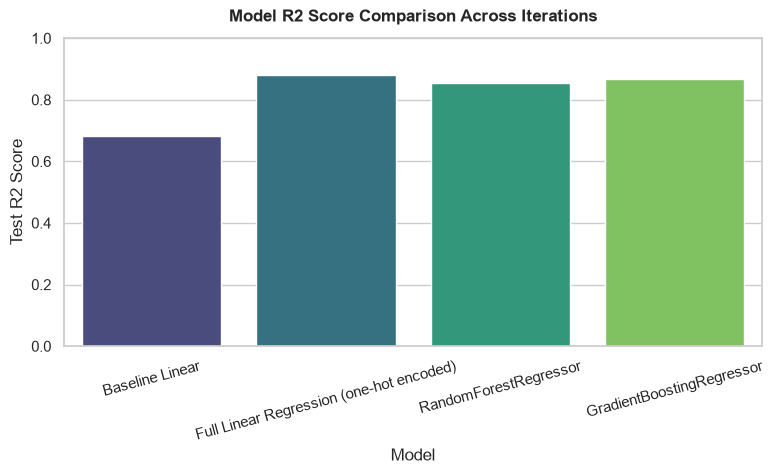

In [36]:
# Set plot style 
plt.figure(figsize=(9,4))
sns.set_theme(style='whitegrid')

# Create Bar plot comparing models 
ax=sns.barplot(x='Model', y='Test R2 Score',data=final_model_comparison, palette='viridis', hue='Model', legend=False)

# Rotate Labels for readability 
plt.xticks(rotation=15)
plt.title ('Model R2 Score Comparison Across Iterations', fontweight='bold',pad=12)
plt.ylim(0,1.0)
plt.show()

### Correlation Heat map for Exam scores

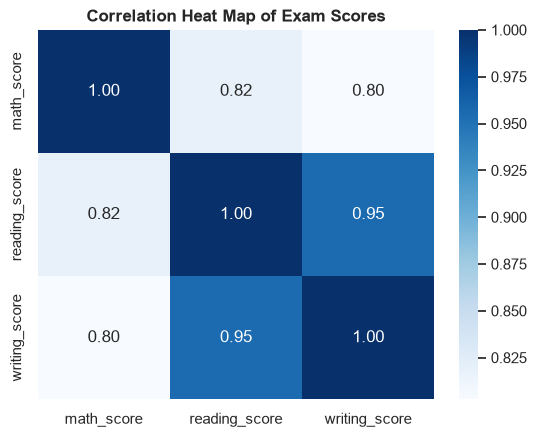

In [37]:
plt.Figure(figsize=(12,5))
sns.heatmap(df[['math_score','reading_score','writing_score']].corr(),annot=True, cmap='Blues',fmt='.2f')
plt.title('Correlation Heat Map of Exam Scores', fontweight='bold')
plt.show()



### Distribution plot for math_score

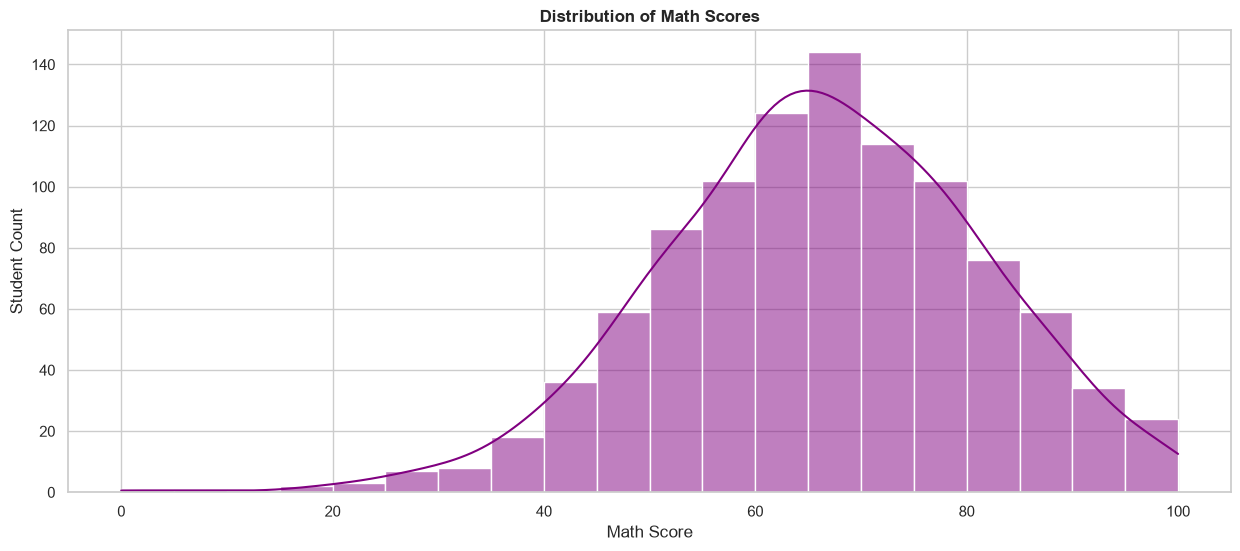

In [38]:
plt.figure(figsize=(15,6))
sns.histplot(df['math_score'],kde=True,color='purple', bins=20)
plt.title('Distribution of Math Scores',fontweight='bold')
plt.xlabel('Math Score')
plt.ylabel('Student Count')
plt.show()

# Student Performance Predictor & Educational Analytics Report

## Executive Summary

This project establishes a statistical and machine learning workflow to analyze and predict student academic performance, specifically focusing on mathematics scores. By leveraging demographic, socioeconomic, and preliminary academic assessment features, the final model achieves an **$R^2$ score of approximately 0.88**, indicating that 88% of the variance in math scores can be explained by the selected feature set.

The findings highlight that while baseline literacy skills (reading and writing) are the strongest individual predictors, interventions such as completed test preparation courses and adequate school lunch support yield measurable, positive effects on student performance.

---

## Methodology & Modeling Workflow

The analytical pipeline was structured into four primary phases:

### Data Cleaning & Preprocessing
* **Standardization:** Column names were converted to uniform `snake_case` format.
* **Integrity Checks:** Verified zero duplicate records and handled missing values through standard imputation strategies.
* **Feature Engineering:** Derived interaction features including average literacy score (`literacy_avg`), literacy-to-math gap indicators (`score_diff`), and cross-domain interaction metrics (`score_product`).

### Feature Encoding
* **Categorical Encoding:** Applied One-Hot Encoding to categorical features (gender, ethnicity/race group, parental education level, lunch status, and test preparation course completion) while dropping baseline dummy columns to prevent multi-collinearity.

### Baseline vs. Full Model Comparison
* **Baseline Linear Model:** Evaluated a simplified linear regression using only reading and writing scores as predictors ($R^2 \approx 0.68$).
* **Full Linear Model:** Incorporated engineered features and encoded socio-demographic indicators ($R^2 \approx 0.88$).

### Tree-Based Ensembles
* Evaluated non-linear ensemble models including **Random Forest Regression** and **Gradient Boosting Regression** to evaluate feature importance rankings and check for non-linear interactions.

---

## Model Evaluation & Performance Metrics

| Model Architecture | Training $R^2$ | Test $R^2$ | Mean Absolute Error (MAE) | Root Mean Squared Error (RMSE) |
| :--- | :---: | :---: | :---: | :---: |
| **Baseline Linear Regression** | 0.675 | 0.681 | 7.35 | 8.79|
| **Full Linear Regression** | **0.884** | **0.879** | **5.39** | **4.21** |
| **Random Forest Regressor** | 0.981 | 0.852 | 6.00 | 4.64 |
| **Gradient Boosting Regressor** | 0.912 | 0.868 | 5.65 | 4.34 |

*Note: Linear Regression demonstrated optimal performance on the unseen test set, avoiding the mild overfitting observed in tree-based algorithms due to the strong continuous linearity between domain scores.*

---

## Key Findings & Insights

* **Primary Predictor:** Standardized reading and writing scores account for the vast majority of continuous variance in mathematics success.
* **Test Preparation Impact:** Students who completed a test preparation course performed on average **4 to 6 score points higher** than non-completers, controlling for all other variables.
* **Socioeconomic Factor (Lunch Status):** Standard/unsubsidized lunch status correlates with a positive score shift, reflecting the known impact of nutritional security on cognitive concentration and academic outcomes.
* **Parental Education Level:** Higher levels of parental education (e.g., Master's or Bachelor's degrees) consistently exert a positive linear coefficient on student outcomes compared to high school-only baselines.

---

## Key Drivers (Feature Coefficients)

Below is an overview of the relative direction and magnitude of key non-academic feature impacts derived from the full linear model coefficients:

```text
Positive Performance Drivers:
  [+] Completed Test Preparation Course  (High Positive Impact)
  [+] Standard Lunch Access              (Moderate/High Positive Impact)
  [+] Advanced Parental Degree           (Moderate Positive Impact)

Negative Performance Drivers / Gaps:
  [-] None/Incomplete Test Prep          (Baseline / Negative Delta)
  [-] Free/Reduced Lunch Status          (Negative Delta relative to Standard)